   study_hours  attendance  previous_marks  final_marks
0            5          65              55           58
1           10          80              70           74
2           15          90              82           88
3            3          50              45           42
4           12          85              76           81
First 5 rows:
   study_hours  attendance  previous_marks  final_marks
0            5          65              55           58
1           10          80              70           74
2           15          90              82           88
3            3          50              45           42
4           12          85              76           81

Dataset shape:
(5, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   study_hours     5 non-null      int64
 1   attendance      5 non-null      int

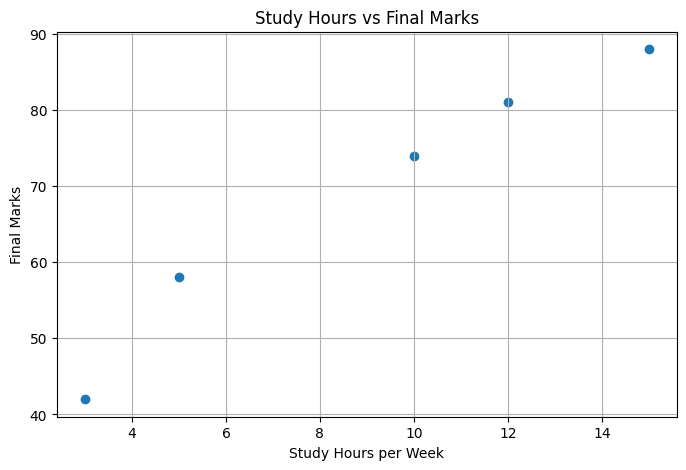

Training samples: 3
Testing samples: 2
Model training completed successfully!
Predicted final marks: 70.78
   study_hours  attendance  previous_marks  predicted_final_marks
0            4          55              45                  46.18
1            8          75              65                  69.76
2           12          85              78                  82.51
3           15          95              90                  94.95
Actual marks:     [74, 81]
Predicted marks:  [75.62 81.82]
-------------------
MAE: 1.22
MSE: 1.65
RMSE: 1.29
R² Score: 0.87


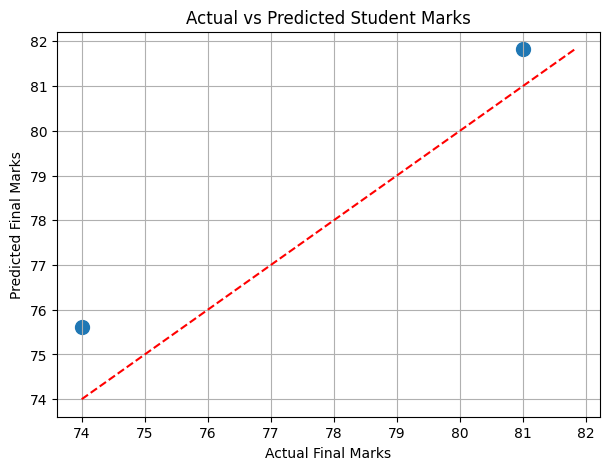

NameError: name 'urllib' is not defined

In [1]:
import pandas as pd

data = {
    "study_hours": [5, 10, 15, 3, 12],
    "attendance": [65, 80, 90, 50, 85],
    "previous_marks": [55, 70, 82, 45, 76],
    "final_marks": [58, 74, 88, 42, 81]
}

df = pd.DataFrame(data)

print(df)


# 1. Display the first few rows
print("First 5 rows:")
print(df.head())

# 2. Check the number of rows and columns
print("\nDataset shape:")
print(df.shape)

# 3. Check column data types
print("\nDataset information:")
df.info()

# 4. Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# 5. Get basic statistics
print("\nStatistical summary:")
print(df.describe())


import matplotlib.pyplot as plt

# Plot study hours against final marks
plt.figure(figsize=(8, 5))
plt.scatter(
    df["study_hours"],
    df["final_marks"],
    marker="o"
)

plt.xlabel("Study Hours per Week")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")
plt.grid(True)

plt.show()

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Input features (X)
X = df[["study_hours", "attendance", "previous_marks"]]

# Target value (y)
y = df["final_marks"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Create the model
model = LinearRegression()

# Train it using the training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

# Details of a new student
new_student = pd.DataFrame({
    "study_hours": [8],
    "attendance": [75],
    "previous_marks": [68]
})

# Predict the student's final marks
predicted_marks = model.predict(new_student)

print("Predicted final marks:", round(predicted_marks[0], 2))

students = pd.DataFrame({
    "study_hours": [4, 8, 12, 15],
    "attendance": [55, 75, 85, 95],
    "previous_marks": [45, 65, 78, 90]
})

students["predicted_final_marks"] = model.predict(students)

print(students.round(2))

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predict marks for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Actual marks:    ", list(y_test))
print("Predicted marks: ", np.round(y_pred, 2))
print("-------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 2))


import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, s=100)

# Perfect-prediction reference line
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title("Actual vs Predicted Student Marks")
plt.grid(True)
plt.show()


import io

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = urllib.request.urlopen(url)

with zipfile.ZipFile(io.BytesIO(response.read())) as z:
    csv_files = [
        name for name in z.namelist()
        if name.endswith("student-mat.csv")
    ]

    if not csv_files:
        print("CSV not found. Available files:")
        print(z.namelist())
    else:
        with z.open(csv_files[0]) as f:
            real_df = pd.read_csv(f, sep=";")

        print("Dataset loaded successfully!")
        print("Dataset shape:", real_df.shape)
        display(real_df.head())

import pandas as pd
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download the outer ZIP
response = urllib.request.urlopen(url)

with zipfile.ZipFile(io.BytesIO(response.read())) as outer_zip:

    # Open the ZIP file inside it
    inner_zip_bytes = outer_zip.read("student.zip")

    with zipfile.ZipFile(io.BytesIO(inner_zip_bytes)) as inner_zip:

        print("Files inside the inner ZIP:")
        print(inner_zip.namelist())

        # Find the mathematics dataset
        csv_file = next(
            name for name in inner_zip.namelist()
            if name.endswith("student-mat.csv")
        )

        # Load the CSV into a DataFrame
        with inner_zip.open(csv_file) as f:
            real_df = pd.read_csv(f, sep=";")

print("\nDataset loaded successfully!")
print("Dataset shape:", real_df.shape)
display(real_df.head())


# Check dataset dimensions
print("Dataset shape:", real_df.shape)

# Check missing values
print("\nMissing values in each column:")
print(real_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", real_df.duplicated().sum())

# Check final-grade distribution
print("\nFinal grade statistics:")
print(real_df["G3"].describe())

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Choose input features
features = [
    "studytime",
    "absences",
    "age",
    "failures",
    "health",
    "G1",
    "G2"
]

X = real_df[features]
y = real_df["G3"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

model_real = LinearRegression()

model_real.fit(X_train, y_train)

print("Real dataset model trained successfully!")

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Predict grades for the test set
y_pred_real = model_real.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred_real)
mse = mean_squared_error(y_test, y_pred_real)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_real)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.3f}")


import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_real, alpha=0.7)

# Reference line for perfect predictions
plt.plot([0, 20], [0, 20], "r--", label="Perfect prediction")

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.legend()
plt.grid(True)
plt.show()

# Predict a new student's final grade

import pandas as pd

new_student = pd.DataFrame([{
    "studytime": 2,
    "absences": 4,
    "age": 17,
    "failures": 0,
    "health": 4,
    "G1": 12,
    "G2": 13
}])

predicted_grade = model_real.predict(new_student)[0]

# Grades in this dataset range from 0 to 20
predicted_grade = max(0, min(20, predicted_grade))

print("Student Academic Performance Prediction")
print("----------------------------------------")
print(f"Predicted final grade: {predicted_grade:.2f} / 20")

import pandas as pd

def predict_student_grade(studytime, absences, age,
                          failures, health, G1, G2):
    student = pd.DataFrame([{
        "studytime": studytime,
        "absences": absences,
        "age": age,
        "failures": failures,
        "health": health,
        "G1": G1,
        "G2": G2
    }])

    prediction = model_real.predict(student)[0]
    prediction = max(0, min(20, prediction))

    print(f"Predicted final grade: {prediction:.2f} / 20")

    return prediction

# Example
predict_student_grade(
    studytime=2,
    absences=4,
    age=17,
    failures=0,
    health=4,
    G1=12,
    G2=13
)

import pandas as pd

def predict_student_grade(studytime, absences, age,
                          failures, health, G1, G2):
    student = pd.DataFrame([{
        "studytime": studytime,
        "absences": absences,
        "age": age,
        "failures": failures,
        "health": health,
        "G1": G1,
        "G2": G2
    }])

    prediction = float(model_real.predict(student)[0])
    prediction = max(0.0, min(20.0, prediction))

    print("STUDENT ACADEMIC PERFORMANCE PREDICTION")
    print("---------------------------------------")
    print(f"Predicted final grade: {prediction:.2f} / 20")

# Test the function
predict_student_grade(
    studytime=2,
    absences=4,
    age=17,
    failures=0,
    health=4,
    G1=12,
    G2=13
)

import pandas as pd

# Enter a NEW student's data
new_student = pd.DataFrame([{
    "studytime": 3,
    "absences": 2,
    "age": 16,
    "failures": 0,
    "health": 5,
    "G1": 14,
    "G2": 15
}])

# Predict the final grade
prediction = float(model_real.predict(new_student)[0])

# Keep prediction within the dataset's grade range
prediction = max(0, min(20, prediction))

print("NEW STUDENT PREDICTION")
print("----------------------")
print("Study time:", new_student["studytime"].iloc[0])
print("Absences:", new_student["absences"].iloc[0])
print("Previous grade G1:", new_student["G1"].iloc[0])
print("Previous grade G2:", new_student["G2"].iloc[0])
print(f"Predicted final grade: {prediction:.2f} / 20")


import urllib.request
import zipfile
import io
import pandas as pd

print("All required libraries are imported!")






In [ ]:

import urllib.request
import zipfile
import io
import pandas as pd

print("All required libraries are imported!")


# Import everything needed
import urllib.request
import zipfile
import io
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download dataset
with urllib.request.urlopen(url) as response:
    downloaded_data = response.read()

# Open the outer ZIP file
with zipfile.ZipFile(io.BytesIO(downloaded_data)) as outer_zip:
    # Open the nested ZIP file
    inner_data = outer_zip.read("student.zip")

    with zipfile.ZipFile(io.BytesIO(inner_data)) as inner_zip:
        csv_file = next(
            name for name in inner_zip.namelist()
            if name.endswith("student-mat.csv")
        )

        with inner_zip.open(csv_file) as file:
            real_df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", real_df.shape)
display(real_df.head())

print(real_df.shape)
print(model_real)
print(features)

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Select the input features
features = [
    "studytime",
    "absences",
    "age",
    "failures",
    "health",
    "G1",
    "G2"
]

# Separate inputs (X) and target (y)
X = real_df[features]
y = real_df["G3"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model_real = LinearRegression()
model_real.fit(X_train, y_train)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))




All required libraries are imported!
Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


(395, 33)


NameError: name 'model_real' is not defined

In [2]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Select the input features
features = [
    "studytime",
    "absences",
    "age",
    "failures",
    "health",
    "G1",
    "G2"
]

# Separate inputs (X) and target (y)
X = real_df[features]
y = real_df["G3"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model_real = LinearRegression()
model_real.fit(X_train, y_train)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


print("Dataset shape:", real_df.shape)
print("Model:", model_real)
print("Features:", features)


print("Dataset shape:", real_df.shape)
print("Model:", model_real)
print("Features:", features)


import pandas as pd

new_student = pd.DataFrame([{
    "studytime": 5,
    "absences": 2,
    "age": 17,
    "failures": 0,
    "health": 2,
    "G1": 18,
    "G2": 17
}])

prediction = float(model_real.predict(new_student[features])[0])
prediction = max(0.0, min(20.0, prediction))

print(f"Predicted final grade: {prediction:.2f} / 20")


NameError: name 'real_df' is not defined

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Input shape: (395, 7)
Target shape: (395,)
Model trained successfully!
Predicted Final Grade: 18.90 / 20
Predictions generated successfully!


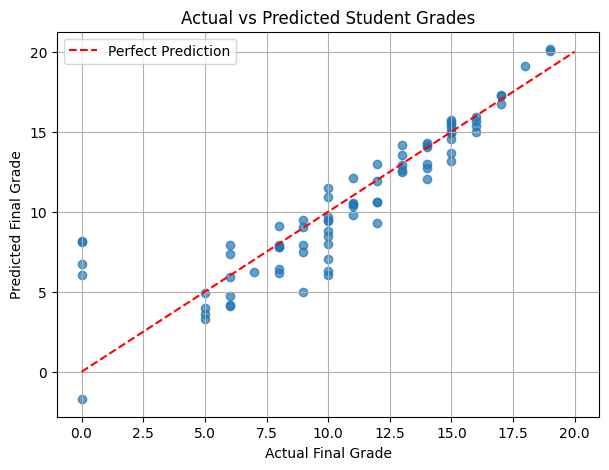

In [15]:

import urllib.request
import zipfile
import io
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download dataset
with urllib.request.urlopen(url) as response:
    downloaded_data = response.read()

# Extract nested ZIP files
with zipfile.ZipFile(io.BytesIO(downloaded_data)) as outer_zip:
    inner_data = outer_zip.read("student.zip")

    with zipfile.ZipFile(io.BytesIO(inner_data)) as inner_zip:
        csv_file = next(
            name for name in inner_zip.namelist()
            if name.endswith("student-mat.csv")
        )

        with inner_zip.open(csv_file) as file:
            real_df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", real_df.shape)
display(real_df.head())


features = [
    "studytime",
    "absences",
    "age",
    "failures",
    "health",
    "G1",
    "G2"
]

X = real_df[features]
y = real_df["G3"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_real = LinearRegression()
model_real.fit(X_train, y_train)

print("Model trained successfully!")

new_student = pd.DataFrame([{
    "studytime": 9,
    "absences": 0,
    "age": 17,
    "failures": 0,
    "health": 2,
    "G1": 18,
    "G2": 19
}])

prediction = model_real.predict(new_student[features])[0]
prediction = max(0, min(20, prediction))

print(f"Predicted Final Grade: {prediction:.2f} / 20")


y_pred_real = model_real.predict(X_test)

print("Predictions generated successfully!")

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_real, alpha=0.7)
plt.plot([0, 20], [0, 20], "r--", label="Perfect Prediction")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")

plt.legend()
plt.grid(True)
plt.show()